In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import auc, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
pd.set_option('max_colwidth', 500)
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Load files
train = pd.read_csv('Train.csv')
test = pd.read_csv('Test.csv')
samplesubmission = pd.read_csv('SampleSubmission.csv')
variable_definations = pd.read_csv('VariableDefinitions.csv')

In [4]:
# Preview the first five rows of the train set
train.head()

,User_ID,month,year,CompPart,Comment,Sub,Disc,Target
0,ID_XI7BAR4Y,8,3,0,0,0,0,0
1,ID_XI7BAR4Y,8,2,0,0,0,0,0
2,ID_XI7BAR4Y,9,2,0,0,0,0,0
3,ID_XI7BAR4Y,9,3,0,0,0,0,0
4,ID_XI7BAR4Y,10,3,0,0,0,0,0


In [5]:
# Preview the first five rows of the test set
test.head()

,User_ID,month,year
0,ID_H1ELY25E,1,4
1,ID_H1ELY25E,2,4
2,ID_H1ELY25E,3,4
3,ID_463Q2BCO,1,4
4,ID_463Q2BCO,2,4


In [6]:
# Preview the first five rows of the sample submission file
samplesubmission.head()

,UserMonthYear,Target
0,ID_000VV0KM_1_4,NaN
1,ID_000VV0KM_2_4,NaN
2,ID_000VV0KM_3_4,NaN
3,ID_003OCIYO_1_4,NaN
4,ID_003OCIYO_2_4,NaN


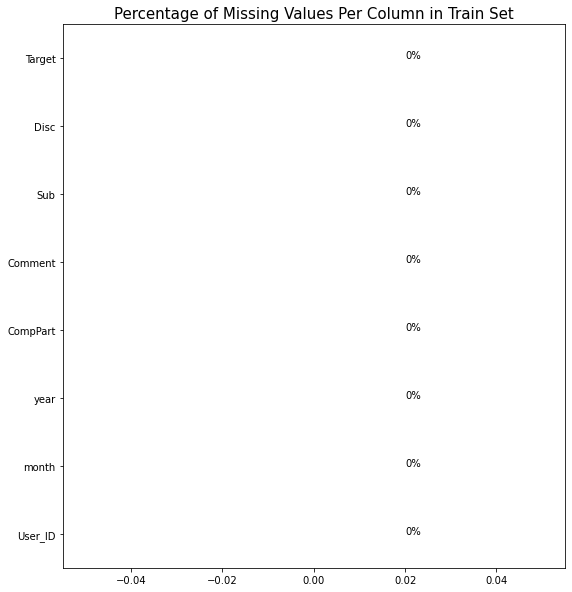

In [7]:
# Check if there any missing values in train set
ax = train.isna().sum().sort_values().plot(kind = 'barh', figsize = (9, 10))
plt.title('Percentage of Missing Values Per Column in Train Set', fontdict={'size':15})
for p in ax.patches:
    percentage ='{:,.0f}%'.format((p.get_width()/train.shape[0])*100)
    width, height =p.get_width(),p.get_height()
    x=p.get_x()+width+0.02
    y=p.get_y()+height/2
    ax.annotate(percentage,(x,y))

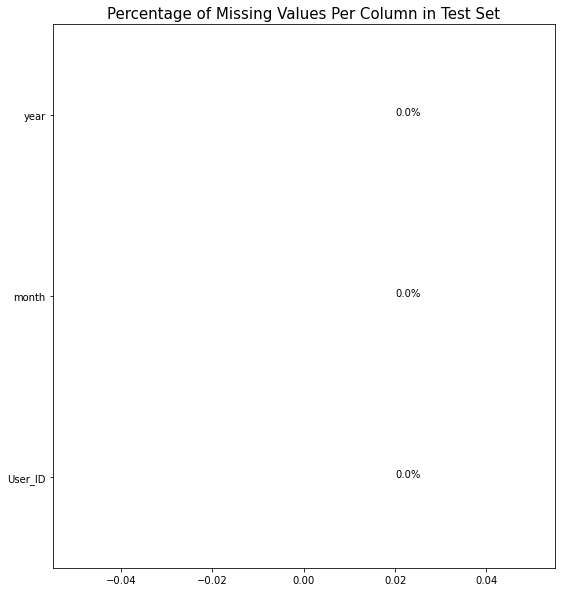

In [8]:
# Check if there missing values in test set
ax = test.isna().sum().sort_values().plot(kind = 'barh', figsize = (9, 10))
plt.title('Percentage of Missing Values Per Column in Test Set', fontdict={'size':15})

for p in ax.patches:
    percentage ='{:,.1f}%'.format((p.get_width()/test.shape[0])*100)
    width, height =p.get_width(),p.get_height()
    x=p.get_x()+width+0.02
    y=p.get_y()+height/2
    ax.annotate(percentage,(x,y))

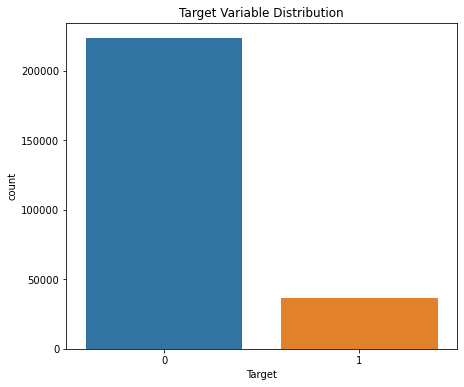

In [9]:
plt.figure(figsize=(7, 6))
sns.countplot(train.Target)
plt.title('Target Variable Distribution');

In [10]:
print(train.info())
print(test.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 259832 entries, 0 to 259831
Data columns (total 8 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   User_ID   259832 non-null  object
 1   month     259832 non-null  int64 
 2   year      259832 non-null  int64 
 3   CompPart  259832 non-null  int64 
 4   Comment   259832 non-null  int64 
 5   Sub       259832 non-null  int64 
 6   Disc      259832 non-null  int64 
 7   Target    259832 non-null  int64 
dtypes: int64(7), object(1)
memory usage: 15.9+ MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65223 entries, 0 to 65222
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   User_ID  65223 non-null  object
 1   month    65223 non-null  int64 
 2   year     65223 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 1.5+ MB
None


In [11]:
x=train[['month','year']]
y=train['Target']

In [12]:
model = RandomForestClassifier()
model.fit(x,y)

RandomForestClassifier()

In [13]:
model.score(x,y)

0.8612642014840358

In [14]:
t = test[['month','year']]
result = model.predict(t)

In [15]:
print(model.score(x,y))

0.8612642014840358


In [16]:
result=pd.DataFrame(result)

In [17]:
test1=pd.read_csv('test.csv')
test1['UserMonthYear'] = test1['User_ID'].astype(str)+'_'+test1['month'].astype(str)+'_'+test1['year'].astype(str)
test1

,User_ID,month,year,UserMonthYear
0,ID_H1ELY25E,1,4,ID_H1ELY25E_1_4
1,ID_H1ELY25E,2,4,ID_H1ELY25E_2_4
2,ID_H1ELY25E,3,4,ID_H1ELY25E_3_4
3,ID_463Q2BCO,1,4,ID_463Q2BCO_1_4
4,ID_463Q2BCO,2,4,ID_463Q2BCO_2_4
...,...,...,...,...
65218,ID_4XKWR8UN,3,4,ID_4XKWR8UN_3_4
65219,ID_L54061S5,3,4,ID_L54061S5_3_4
65220,ID_I3C1N5RO,3,4,ID_I3C1N5RO_3_4
65221,ID_WWNR6I15,3,4,ID_WWNR6I15_3_4


In [18]:
idd=pd.DataFrame(test1['UserMonthYear'])
result['UserMonthYear']=idd
result.columns=['Target','UserMonthYear']
result = np.fliplr(result)
result=pd.DataFrame(result)
result.columns=['UserMonthYear','Target']
result

,UserMonthYear,Target
0,ID_H1ELY25E_1_4,0
1,ID_H1ELY25E_2_4,0
2,ID_H1ELY25E_3_4,0
3,ID_463Q2BCO_1_4,0
4,ID_463Q2BCO_2_4,0
...,...,...
65218,ID_4XKWR8UN_3_4,0
65219,ID_L54061S5_3_4,0
65220,ID_I3C1N5RO_3_4,0
65221,ID_WWNR6I15_3_4,0


In [19]:
# result.head()

In [20]:
# result.isna().sum()

In [21]:
# result.to_csv("result.csv", index = False)

DATA INTEGRATION

In [22]:
Ncomments = pd.read_csv('Projet-Zindi-Zindi-User-Behaviour-Birthday-Challenge-main/Data_Clean/comment_counter.csv')
Ncompetitions = pd.read_csv('Projet-Zindi-Zindi-User-Behaviour-Birthday-Challenge-main/Data_Clean/Competitions_Clean.csv')
Ndiscussions = pd.read_csv('Projet-Zindi-Zindi-User-Behaviour-Birthday-Challenge-main/Data_Clean/discussions_counter.csv')
Nsubmissions = pd.read_csv('Projet-Zindi-Zindi-User-Behaviour-Birthday-Challenge-main/Data_Clean/submission_counter.csv')
Nparticipations = pd.read_csv('Projet-Zindi-Zindi-User-Behaviour-Birthday-Challenge-main/Data_Clean/Succeful_sub.csv')
Nusers = pd.read_csv('Projet-Zindi-Zindi-User-Behaviour-Birthday-Challenge-main/Data_Clean/users_Clean.csv')

In [23]:
Ncomments.drop_duplicates(subset=['User_ID'],inplace = True)
# Ncompetitions.drop_duplicates(inplace = True)
Ndiscussions.drop_duplicates(subset=['User_ID'],inplace = True)
Nsubmissions.drop_duplicates(subset=['User_ID'],inplace = True)
# Nparticipations.drop_duplicates(inplace = True)
Nusers.drop_duplicates(subset=['UserID'],inplace = True)

In [24]:
Ntrain = (train.merge(Ncomments, how='left', on='User_ID').merge(Ndiscussions, on='User_ID').merge(Nsubmissions, on='User_ID'))

In [25]:
Ntrain.head()

,User_ID,month,year,CompPart,Comment,Sub,Disc,Target,comment_counter,discussions_counter,submission_counter
0,ID_YYGB4Q8H,8,3,0,0,0,0,0,0.0,4,6
1,ID_YYGB4Q8H,9,3,0,0,0,0,0,0.0,4,6
2,ID_YYGB4Q8H,10,3,1,1,1,1,1,0.0,4,6
3,ID_YYGB4Q8H,11,3,1,1,1,1,1,0.0,4,6
4,ID_YYGB4Q8H,12,3,1,1,1,1,1,0.0,4,6


In [26]:
Ntrain = Ntrain.drop(['comment_counter'],axis=1)

In [27]:
Ntest = Ntest.drop(['comment_counter'],axis=1)

NameError: name 'Ntest' is not defined

In [43]:
Ntrain.head()

,User_ID,month,year,CompPart,Comment,Sub,Disc,Target,discussions_counter,submission_counter
0,ID_YYGB4Q8H,8,3,0,0,0,0,0,4,6
1,ID_YYGB4Q8H,9,3,0,0,0,0,0,4,6
2,ID_YYGB4Q8H,10,3,1,1,1,1,1,4,6
3,ID_YYGB4Q8H,11,3,1,1,1,1,1,4,6
4,ID_YYGB4Q8H,12,3,1,1,1,1,1,4,6


In [36]:
Ntest = (test.merge(Nsubmissions, how='left', on='User_ID').merge(Ndiscussions, how='left', on='User_ID'))

In [37]:
Ntest.head()

,User_ID,month,year,submission_counter,discussions_counter
0,ID_H1ELY25E,1,4,NaN,NaN
1,ID_H1ELY25E,2,4,NaN,NaN
2,ID_H1ELY25E,3,4,NaN,NaN
3,ID_463Q2BCO,1,4,1.0,NaN
4,ID_463Q2BCO,2,4,1.0,NaN


In [40]:
type(Ntest)

pandas.core.frame.DataFrame

In [42]:
Ntest.fillna(0)
Ntest.head()

,User_ID,month,year,submission_counter,discussions_counter
0,ID_H1ELY25E,1,4,0.0,0.0
1,ID_H1ELY25E,2,4,0.0,0.0
2,ID_H1ELY25E,3,4,0.0,0.0
3,ID_463Q2BCO,1,4,1.0,0.0
4,ID_463Q2BCO,2,4,1.0,0.0


In [45]:
# x_new.dropna(axis=0,inplace=True)
# y_new.dropna(axis=0,inplace=True)
x_new = Ntrain[['month','year','discussions_counter','submission_counter']]
y_new = Ntrain['Target']
print(x_new.isna().sum())
print(y_new.isna().sum())

month                  0
year                   0
discussions_counter    0
submission_counter     0
dtype: int64
0


In [38]:
print(Ntest.shape)

(65223, 5)


In [46]:
rf_model = RandomForestClassifier()
rf_model.fit(x_new,y_new)
rf_prediction = rf_model.predict(Ntest[['month','year','discussions_counter','submission_counter']])

In [47]:
pred = pd.DataFrame(rf_prediction)

In [48]:
pred.sum()

0    6270
dtype: int64

In [49]:
result.Target=pred

In [50]:
result.head()

,UserMonthYear,Target
0,ID_H1ELY25E_1_4,0
1,ID_H1ELY25E_2_4,0
2,ID_H1ELY25E_3_4,0
3,ID_463Q2BCO_1_4,0
4,ID_463Q2BCO_2_4,0


In [51]:
result.to_csv("result3.csv", index = False)

<AxesSubplot:xlabel='Target', ylabel='count'>

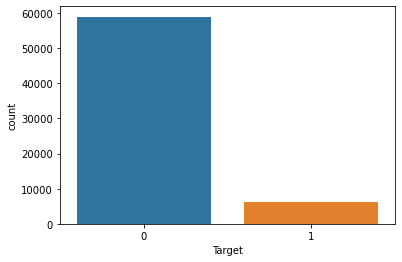

In [52]:
sns.countplot(result.Target)

In [ ]:
result.shape